# 04. Comparación de movilidad durante incidencias de Rodalies

## 1. Objetivo y metodología

Este notebook analiza las variaciones de movilidad intermunicipal que coinciden con incidencias relevantes de Rodalies en la provincia de Barcelona.

El análisis utiliza los viajes diarios agregados de Telefónica y el modelo de regresión seleccionado en el Notebook 02 para estimar la movilidad habitual en cada relación origen-destino (OD).

Para cada incidencia se seguirá el siguiente procedimiento:

1. Identificar la fecha, duración, líneas y tramo afectados.
2. Seleccionar los municipios y relaciones OD vinculados geográficamente con el episodio.
3. Estimar los viajes esperados y compararlos con los observados.
4. Contrastar las desviaciones con días comparables y relaciones de control.
5. Visualizar los resultados temporal y territorialmente.

El objetivo es identificar alteraciones observables que coinciden con incidencias ferroviarias, sin atribuirles automáticamente una relación causal.

**Limitación principal:** los datos de Telefónica representan viajes diarios agregados, sin identificar el modo de transporte, los horarios de desplazamiento ni las rutas realizadas.

In [17]:

from pathlib import Path

import pandas as pd
import numpy as np
import duckdb
import holidays
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

# Rutas del proyecto
PROJECT_ROOT = Path.cwd().resolve().parent
DATA_DIR = PROJECT_ROOT / "data"

M2_PATH = DATA_DIR / "processed" / "telefonica" / "M2.parquet"

# Ajustar esta ruta si el Excel está en otra carpeta
INCIDENCIAS_PATH = DATA_DIR / "raw" / "rodalies" / \
    "RMOVE_Incidencias_Barcelona_Jul2024_Ago2025_v07.xlsx"

# Conexión DuckDB
con = duckdb.connect()

# Festivos oficiales de Cataluña
festivos_cat = holidays.country_holidays(
    "ES",
    subdiv="CT",
    years=[2023, 2024, 2025]
)

print("M2 encontrado:", M2_PATH.exists())
print("Excel encontrado:", INCIDENCIAS_PATH.exists())


M2 encontrado: True
Excel encontrado: True



## 2. Selección de incidencias relevantes

Se utiliza el registro histórico consolidado de incidencias ferroviarias de R-MOVE.

Se priorizan episodios con interrupciones importantes, afectación a varias líneas o tramos y suficiente documentación para identificar los municipios potencialmente afectados.

Como primeros casos de estudio se seleccionan:

- **7 de marzo de 2025 (Y25-004):** incidencia de catenaria en Bellvitge-Gornal–El Prat de Llobregat.
- **5 de junio de 2025 (Y25-013):** incidencia en el túnel ferroviario de Barcelona, cerca de Plaça de Catalunya.

La selección se basa en las características documentadas de las incidencias y no en los resultados de movilidad, para evitar escoger únicamente los episodios que presentan mayores desviaciones.


In [18]:

incidencias = pd.read_excel(
    INCIDENCIAS_PATH,
    sheet_name="Incidencias Barcelona"
)

incidencias["Fecha"] = pd.to_datetime(
    incidencias["Fecha"]
)

# Casos de estudio iniciales
ids_seleccionados = ["Y25-004", "Y25-013"]

incidencias_seleccionadas = (
    incidencias[
        incidencias["ID"].isin(ids_seleccionados)
    ]
    .sort_values("Fecha")
    .copy()
)

columnas_mostrar = [
    "ID",
    "Fecha",
    "Líneas afectadas",
    "Lugar / tramo",
    "Afectación documentada",
    "Horario / duración",
    "URL verificable"
]

display(incidencias_seleccionadas[columnas_mostrar])


,ID,Fecha,Líneas afectadas,Lugar / tramo,Afectación documentada,Horario / duración,URL verificable
86,Y25-004,2025-03-07,R2; R2 Nord; R2 Sud; R14; R15; R16; R17,Bellvitge-Gornal–El Prat de Llobregat,Tramo interrumpido durante horas; vía única; e...,Mañana; vía única ~10:40; doble vía ~14:00,https://beteve.cat/mobilitat/tallada-circulaci...
95,Y25-013,2025-06-05,R1; R2; R3; R4,"Túnel ferroviario de Barcelona, cerca de Plaça...",Alteraciones en varias líneas centrales; 155 t...,14:25–16:14 (registro oficial),https://www.3cat.cat/3catinfo/el-mapa-dels-ret...



## 3. Selección de corredores y relaciones OD

### 3.1. Corredor sur: incidencia del 7 de marzo de 2025

La primera incidencia seleccionada afectó a la circulación ferroviaria en el entorno de Bellvitge y El Prat de Llobregat.

Se analizarán las relaciones de movilidad entre Barcelona y los municipios del corredor sur, así como los desplazamientos entre estos municipios.

La selección inicial se realiza por proximidad geográfica y relación con el corredor afectado, antes de observar las desviaciones de movilidad.

Se comprobará el volumen habitual de cada relación para descartar aquellas cuyo número reducido de viajes dificulte una interpretación fiable.

Los municipios seleccionados representan un ámbito territorial de análisis, no trayectorias individuales ni rutas ferroviarias efectivamente utilizadas.


In [19]:

# Municipios candidatos del corredor sur
municipios_sur = {
    "08019": "Barcelona",
    "08169": "El Prat de Llobregat",
    "08301": "Viladecans",
    "08089": "Gavà",
    "08056": "Castelldefels"
}

# Relaciones dirigidas entre municipios distintos
relaciones_sur = []

for codigo_origen, nombre_origen in municipios_sur.items():
    for codigo_destino, nombre_destino in municipios_sur.items():

        if codigo_origen == codigo_destino:
            continue

        relaciones_sur.append({
            "municipio_origen": codigo_origen,
            "municipio_destino": codigo_destino,
            "Relacion": f"{nombre_origen} → {nombre_destino}"
        })

relaciones_sur = pd.DataFrame(relaciones_sur)

print("Relaciones candidatas:", len(relaciones_sur))
display(relaciones_sur)


Relaciones candidatas: 20


,municipio_origen,municipio_destino,Relacion
0,08019,08169,Barcelona → El Prat de Llobregat
1,08019,08301,Barcelona → Viladecans
2,08019,08089,Barcelona → Gavà
3,08019,08056,Barcelona → Castelldefels
4,08169,08019,El Prat de Llobregat → Barcelona
5,08169,08301,El Prat de Llobregat → Viladecans
6,08169,08089,El Prat de Llobregat → Gavà
7,08169,08056,El Prat de Llobregat → Castelldefels
8,08301,08019,Viladecans → Barcelona
9,08301,08169,Viladecans → El Prat de Llobregat


In [20]:

# Consultar volumen diario medio por relación OD en 2024
volumen_od = con.execute(
    """
    WITH viajes_diarios AS (
        SELECT
            municipio_origen,
            municipio_destino,
            day,
            SUM(viajes) AS viajes
        FROM read_parquet(?)
        WHERE day >= '2024-01-01'
          AND day < '2025-01-01'
          AND municipio_origen IN (SELECT unnest(?))
          AND municipio_destino IN (SELECT unnest(?))
          AND municipio_origen <> municipio_destino
        GROUP BY
            municipio_origen,
            municipio_destino,
            day
    )
    SELECT
        municipio_origen,
        municipio_destino,
        COUNT(*) AS dias_observados,
        AVG(viajes) AS viajes_medios,
        MEDIAN(viajes) AS viajes_medianos
    FROM viajes_diarios
    GROUP BY municipio_origen, municipio_destino
    """,
    [
        str(M2_PATH),
        list(municipios_sur.keys()),
        list(municipios_sur.keys())
    ]
).df()

# Incorporar los nombres de las relaciones
volumen_sur = relaciones_sur.merge(
    volumen_od,
    on=["municipio_origen", "municipio_destino"],
    how="left"
)

display(
    volumen_sur[
        ["Relacion", "dias_observados",
         "viajes_medios", "viajes_medianos"]
    ]
    .sort_values("viajes_medios", ascending=False)
    .round(2)
)


,Relacion,dias_observados,viajes_medios,viajes_medianos
0,Barcelona → El Prat de Llobregat,365,66753.29,67179.0
4,El Prat de Llobregat → Barcelona,365,64778.19,64348.0
3,Barcelona → Castelldefels,365,14111.94,14650.0
16,Castelldefels → Barcelona,365,13997.04,14498.0
1,Barcelona → Viladecans,365,13947.40,15099.0
8,Viladecans → Barcelona,365,13566.34,14905.0
12,Gavà → Barcelona,365,9437.04,10104.0
2,Barcelona → Gavà,365,9203.33,9924.0
18,Castelldefels → Viladecans,365,6038.30,6102.0
11,Viladecans → Castelldefels,365,5931.17,5967.0


In [21]:

UMBRAL_VIAJES = 100

relaciones_sur_analisis = volumen_sur[
    (volumen_sur["viajes_medios"] >= UMBRAL_VIAJES)
    & (volumen_sur["dias_observados"] >= 300)
].copy()

relaciones_sur_analisis = (
    relaciones_sur_analisis
    .sort_values("viajes_medios", ascending=False)
    .reset_index(drop=True)
)

print(
    "Relaciones seleccionadas:",
    len(relaciones_sur_analisis),
    "de",
    len(relaciones_sur)
)

display(
    relaciones_sur_analisis[
        ["Relacion", "viajes_medios", "dias_observados"]
    ].round(2)
)


Relaciones seleccionadas: 20 de 20


,Relacion,viajes_medios,dias_observados
0,Barcelona → El Prat de Llobregat,66753.29,365
1,El Prat de Llobregat → Barcelona,64778.19,365
2,Barcelona → Castelldefels,14111.94,365
3,Castelldefels → Barcelona,13997.04,365
4,Barcelona → Viladecans,13947.40,365
5,Viladecans → Barcelona,13566.34,365
6,Gavà → Barcelona,9437.04,365
7,Barcelona → Gavà,9203.33,365
8,Castelldefels → Viladecans,6038.30,365
9,Viladecans → Castelldefels,5931.17,365



## 4. Estimación de movilidad habitual

### 4.1. Aplicación del modelo de regresión

Se aplica el modelo de regresión lineal desarrollado en el Notebook 02 a las 20 relaciones OD seleccionadas del corredor sur.

El modelo utiliza las siguientes variables:

- Día de la semana.
- Mes.
- Festivos oficiales de Cataluña.
- Tendencia temporal.
- Interacción entre mes y día de la semana.

Para evitar utilizar información posterior a las incidencias estudiadas, el modelo se entrena con los datos de 2023 y 2024 y genera predicciones para 2025.

La diferencia entre los viajes observados y esperados permite identificar variaciones de movilidad, aunque estas no pueden atribuirse directamente a la incidencia ferroviaria.


In [22]:

def estimar_movilidad(codigo_origen, codigo_destino):

    # Obtener viajes diarios
    datos = con.execute(
        """
        SELECT day, SUM(viajes) AS viajes
        FROM read_parquet(?)
        WHERE municipio_origen = ?
          AND municipio_destino = ?
        GROUP BY day
        ORDER BY day
        """,
        [str(M2_PATH), codigo_origen, codigo_destino]
    ).df()

    if datos.empty:
        raise ValueError(
            f"Sin datos: {codigo_origen} → {codigo_destino}"
        )

    datos["day"] = pd.to_datetime(datos["day"])
    datos = datos.set_index("day").sort_index()

    # Calendario completo
    calendario = pd.date_range(
        "2023-01-01", "2025-08-31", freq="D"
    )

    datos = datos.reindex(calendario)
    datos.index.name = "day"

    # Variables explicativas
    datos["dia_semana"] = datos.index.day_of_week
    datos["mes"] = datos.index.month
    datos["t"] = (
        datos.index - pd.Timestamp("2023-01-01")
    ).days

    datos["es_festivo"] = [
        int(fecha.date() in festivos_cat)
        for fecha in datos.index
    ]

    datos["mes_dia"] = (
        datos["mes"].astype(str)
        + "_"
        + datos["dia_semana"].astype(str)
    )

    # Entrenar con 2023-2024
    train = datos.loc[:"2024-12-31"].dropna(
        subset=["viajes"]
    ).copy()

    # Predecir 2025
    test = datos.loc["2025-01-01":"2025-08-31"].copy()

    columnas = [
        "dia_semana", "mes", "t",
        "es_festivo", "mes_dia"
    ]

    categoricas = ["dia_semana", "mes", "mes_dia"]

    X_train = pd.get_dummies(
        train[columnas],
        columns=categoricas,
        drop_first=True,
        dtype=int
    )

    X_test = pd.get_dummies(
        test[columnas],
        columns=categoricas,
        drop_first=True,
        dtype=int
    ).reindex(
        columns=X_train.columns,
        fill_value=0
    )

    modelo = LinearRegression()
    modelo.fit(X_train, train["viajes"])

    # Predicciones diarias
    test["viajes_esperados"] = modelo.predict(X_test)

    # Construir tabla de resultados
    resultado = test[
        ["viajes", "viajes_esperados", "es_festivo"]
    ].copy()

    resultado = resultado.rename(
        columns={"viajes": "viajes_observados"}
    )

    resultado["desviacion"] = (
        resultado["viajes_observados"]
        - resultado["viajes_esperados"]
    )

    resultado["desviacion_pct"] = np.where(
        resultado["viajes_esperados"] > 0,
        100 * resultado["desviacion"]
        / resultado["viajes_esperados"],
        np.nan
    )

    return resultado.reset_index()


In [24]:

# Aplicar la regresión a las 20 relaciones del corredor sur
resultados_od = []

for _, relacion in relaciones_sur_analisis.iterrows():

    origen = relacion["municipio_origen"]
    destino = relacion["municipio_destino"]

    predicciones = estimar_movilidad(origen, destino)

    predicciones["municipio_origen"] = origen
    predicciones["municipio_destino"] = destino
    predicciones["Relacion"] = relacion["Relacion"]

    resultados_od.append(predicciones)

# Unir las predicciones de todas las relaciones
movilidad_esperada = pd.concat(
    resultados_od,
    ignore_index=True
)

print(
    "Relaciones analizadas:",
    movilidad_esperada["Relacion"].nunique()
)

print(
    "Fechas disponibles:",
    movilidad_esperada["day"].nunique()
)

display(movilidad_esperada.head())


Relaciones analizadas: 20
Fechas disponibles: 243


,day,viajes_observados,viajes_esperados,es_festivo,desviacion,desviacion_pct,municipio_origen,municipio_destino,Relacion
0,2025-01-01,45560.0,45401.484456,1,158.515544,0.349142,08019,08169,Barcelona → El Prat de Llobregat
1,2025-01-02,65595.0,62459.080168,0,3135.919832,5.020759,08019,08169,Barcelona → El Prat de Llobregat
2,2025-01-03,65767.0,65698.525949,0,68.474051,0.104225,08019,08169,Barcelona → El Prat de Llobregat
3,2025-01-04,52001.0,50989.275949,0,1011.724051,1.984190,08019,08169,Barcelona → El Prat de Llobregat
4,2025-01-05,51267.0,53649.026297,0,-2382.026297,-4.440018,08019,08169,Barcelona → El Prat de Llobregat


In [25]:

fecha_incidencia = pd.Timestamp("2025-03-07")

resultados_incidencia = movilidad_esperada[
    movilidad_esperada["day"] == fecha_incidencia
].copy()

resultados_incidencia = (
    resultados_incidencia
    .sort_values("desviacion_pct")
    .reset_index(drop=True)
)

display(
    resultados_incidencia[
        [
            "Relacion",
            "viajes_observados",
            "viajes_esperados",
            "desviacion",
            "desviacion_pct"
        ]
    ].round(2)
)


,Relacion,viajes_observados,viajes_esperados,desviacion,desviacion_pct
0,El Prat de Llobregat → Castelldefels,3800.0,6326.71,-2526.71,-39.94
1,Castelldefels → Gavà,3829.0,6248.46,-2419.46,-38.72
2,Gavà → Castelldefels,3896.0,6215.31,-2319.31,-37.32
3,El Prat de Llobregat → Gavà,2617.0,4115.54,-1498.54,-36.41
4,Viladecans → Gavà,1542.0,2354.36,-812.36,-34.50
5,Viladecans → Castelldefels,4486.0,6716.54,-2230.54,-33.21
6,El Prat de Llobregat → Viladecans,3794.0,5655.85,-1861.85,-32.92
7,Gavà → Barcelona,7531.0,10948.79,-3417.79,-31.22
8,Castelldefels → Barcelona,10813.0,15231.80,-4418.80,-29.01
9,Gavà → El Prat de Llobregat,2869.0,4006.82,-1137.82,-28.40



## 5. Comparación con días de referencia

### 5.1. Evaluación de las desviaciones del 7 de marzo de 2025

El análisis inicial muestra desviaciones negativas en las 20 relaciones OD del corredor sur.

Para comprobar si estas desviaciones representan un comportamiento excepcional, se comparan con las registradas en otros viernes próximos a la incidencia.

Se seleccionan días de referencia que cumplen los siguientes criterios:

- Mismo día de la semana que la incidencia.
- Fechas dentro de un intervalo de ±42 días.
- Exclusión de festivos oficiales de Cataluña.
- Exclusión de fechas con incidencias registradas en nuestro histórico.

Para cada relación se compara la desviación del día de incidencia con la distribución de desviaciones de los días seleccionados.

Esta comparación permite contextualizar los resultados, aunque no demuestra que las diferencias sean consecuencia directa de la incidencia ferroviaria.


In [26]:

fecha_incidencia = pd.Timestamp("2025-03-07")

# Fechas con incidencias documentadas en nuestro Excel
fechas_con_incidencias = set(
    pd.to_datetime(incidencias["Fecha"])
    .dt.normalize()
    .dropna()
)

resultados_controles = []

for relacion, grupo in movilidad_esperada.groupby("Relacion"):

    # Resultado del día de incidencia
    dia = grupo[
        grupo["day"] == fecha_incidencia
    ]

    if dia.empty or pd.isna(dia["desviacion_pct"].iloc[0]):
        continue

    desviacion_incidencia = dia["desviacion_pct"].iloc[0]

    # Viernes próximos, excluyendo festivos e incidencias
    controles = grupo[
        (grupo["day"] >= fecha_incidencia - pd.Timedelta(days=42))
        & (grupo["day"] <= fecha_incidencia + pd.Timedelta(days=42))
        & (grupo["day"] != fecha_incidencia)
        & (grupo["day"].dt.dayofweek == fecha_incidencia.dayofweek)
        & (grupo["es_festivo"] == 0)
        & (~grupo["day"].isin(fechas_con_incidencias))
    ].dropna(subset=["desviacion_pct"])

    if controles.empty:
        continue

    residuos = controles["desviacion_pct"]

    resultados_controles.append({
        "Relacion": relacion,
        "Desviacion incidencia (%)": desviacion_incidencia,
        "Mediana controles (%)": residuos.median(),
        "Diferencia (pp)": (
            desviacion_incidencia - residuos.median()
        ),
        "P25 controles (%)": residuos.quantile(0.25),
        "P75 controles (%)": residuos.quantile(0.75),
        "N controles": len(residuos),
        "Por debajo P25": (
            desviacion_incidencia < residuos.quantile(0.25)
        )
    })

comparacion_controles = pd.DataFrame(
    resultados_controles
).sort_values("Diferencia (pp)")

display(comparacion_controles.round(2))


C:\Users\marti\AppData\Local\Temp\ipykernel_137776\1205602708.py:29: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  & (grupo["day"].dt.dayofweek == fecha_incidencia.dayofweek)
C:\Users\marti\AppData\Local\Temp\ipykernel_137776\1205602708.py:29: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  & (grupo["day"].dt.dayofweek == fecha_incidencia.dayofweek)
C:\Users\marti\AppData\Local\Temp\ipykernel_137776\1205602708.py:29: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  & (grupo["day"].dt.dayofweek == fecha_incidencia.dayofweek)
C:\Users\marti\AppData\Local\Temp\ipykernel_137776\1205602708.py:29: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  & (grupo["day"].dt.dayofweek == 

,Relacion,Desviacion incidencia (%),Mediana controles (%),Diferencia (pp),P25 controles (%),P75 controles (%),N controles,Por debajo P25
19,Viladecans → Gavà,-34.50,12.41,-46.92,3.73,22.23,9,True
15,Gavà → Viladecans,-27.91,13.96,-41.87,6.41,33.35,9,True
13,Gavà → Castelldefels,-37.32,1.97,-39.29,-8.85,10.15,9,True
6,Castelldefels → Gavà,-38.72,-2.47,-36.26,-8.41,4.44,9,True
12,Gavà → Barcelona,-31.22,2.83,-34.05,-6.73,3.85,9,True
17,Viladecans → Castelldefels,-33.21,-1.95,-31.26,-9.71,-0.09,9,True
16,Viladecans → Barcelona,-20.22,10.05,-30.28,9.21,18.85,9,True
9,El Prat de Llobregat → Castelldefels,-39.94,-10.45,-29.49,-22.14,-7.18,9,True
7,Castelldefels → Viladecans,-27.94,0.97,-28.91,-0.08,2.57,9,True
3,Barcelona → Viladecans,-19.48,8.26,-27.75,4.33,14.64,9,True



### 5.2. Comparación con relaciones fuera del corredor sur

Las 20 relaciones analizadas presentan desviaciones negativas el 7 de marzo de 2025, todas inferiores al percentil 25 de sus respectivos días de referencia.

Para comprobar si el comportamiento es específico del corredor afectado, se analizan también relaciones OD de otros corredores metropolitanos.

Se aplica el mismo modelo de regresión y el mismo procedimiento de comparación con viernes próximos.

Estas relaciones constituyen referencias territoriales exploratorias, no grupos de control garantizados, puesto que algunas podrían haber experimentado efectos indirectos de la incidencia.

El objetivo es determinar si la reducción de movilidad observada se concentra en el corredor sur o forma parte de una alteración metropolitana más amplia.


In [27]:

# Relaciones de referencia fuera del corredor sur
relaciones_referencia = {
    "Mataró → Barcelona": ("08121", "08019"),
    "Sabadell → Barcelona": ("08187", "08019"),
    "Terrassa → Barcelona": ("08279", "08019"),
    "Granollers → Barcelona": ("08096", "08019"),
    "Martorell → Granollers": ("08114", "08096")
}

resultados_referencia = []

for nombre, (origen, destino) in relaciones_referencia.items():

    predicciones = estimar_movilidad(origen, destino)

    # Resultado de la incidencia
    dia = predicciones[
        predicciones["day"] == fecha_incidencia
    ]

    if dia.empty or pd.isna(dia["desviacion_pct"].iloc[0]):
        continue

    # Viernes comparables
    controles = predicciones[
        (predicciones["day"] >= fecha_incidencia - pd.Timedelta(days=42))
        & (predicciones["day"] <= fecha_incidencia + pd.Timedelta(days=42))
        & (predicciones["day"] != fecha_incidencia)
        & (predicciones["day"].dt.day_of_week == fecha_incidencia.day_of_week)
        & (predicciones["es_festivo"] == 0)
        & (~predicciones["day"].isin(fechas_con_incidencias))
    ].dropna(subset=["desviacion_pct"])

    if controles.empty:
        continue

    desviacion_dia = dia["desviacion_pct"].iloc[0]
    mediana_controles = controles["desviacion_pct"].median()

    resultados_referencia.append({
        "Relacion": nombre,
        "Desviacion incidencia (%)": desviacion_dia,
        "Mediana controles (%)": mediana_controles,
        "Diferencia (pp)": desviacion_dia - mediana_controles,
        "P25 controles (%)": controles["desviacion_pct"].quantile(0.25),
        "P75 controles (%)": controles["desviacion_pct"].quantile(0.75),
        "N controles": len(controles)
    })

comparacion_referencia = pd.DataFrame(
    resultados_referencia
).sort_values("Diferencia (pp)")

display(comparacion_referencia.round(2))


,Relacion,Desviacion incidencia (%),Mediana controles (%),Diferencia (pp),P25 controles (%),P75 controles (%),N controles
4,Martorell → Granollers,-36.04,-2.02,-34.03,-23.74,26.40,9
3,Granollers → Barcelona,-29.85,-2.58,-27.27,-7.28,1.33,9
1,Sabadell → Barcelona,-21.01,4.52,-25.53,2.46,7.03,9
2,Terrassa → Barcelona,-21.95,0.98,-22.93,0.66,3.58,9
0,Mataró → Barcelona,-16.44,-3.11,-13.34,-6.52,-0.61,9



### 5.3. Comprobación del volumen global de movilidad

Las relaciones de referencia exteriores al corredor sur también presentan desviaciones negativas importantes el 7 de marzo de 2025.

Por ello, antes de interpretar las alteraciones observadas como un posible efecto de la incidencia ferroviaria, se comprueba si existe una reducción generalizada del volumen de viajes registrado por Telefónica.

Se compara el total diario de viajes intermunicipales del 7 de marzo con los viernes próximos, utilizando el mismo intervalo temporal de ±42 días.

Esta comprobación permitirá identificar si el episodio coincide con una variación amplia de la movilidad provincial o con un posible problema de cobertura de los datos.


In [28]:

# Total diario de viajes intermunicipales
movilidad_provincial = con.execute(
    """
    SELECT
        day,
        SUM(viajes) AS viajes_totales,
        COUNT(*) AS registros
    FROM read_parquet(?)
    WHERE day BETWEEN '2025-01-24' AND '2025-04-18'
      AND municipio_origen <> municipio_destino
    GROUP BY day
    ORDER BY day
    """,
    [str(M2_PATH)]
).df()

movilidad_provincial["day"] = pd.to_datetime(
    movilidad_provincial["day"]
)

# Seleccionar viernes
viernes = movilidad_provincial[
    movilidad_provincial["day"].dt.day_of_week == 4
].copy()

viernes["es_incidencia"] = (
    viernes["day"] == fecha_incidencia
)

viernes["es_festivo"] = [
    fecha.date() in festivos_cat
    for fecha in viernes["day"]
]

viernes["incidencia_registrada"] = (
    viernes["day"].isin(fechas_con_incidencias)
)

display(
    viernes[
        [
            "day",
            "viajes_totales",
            "registros",
            "es_incidencia",
            "es_festivo",
            "incidencia_registrada"
        ]
    ]
)


,day,viajes_totales,registros,es_incidencia,es_festivo,incidencia_registrada
0,2025-01-24,4555222.0,68616,False,False,False
7,2025-01-31,4554238.0,69280,False,False,False
14,2025-02-07,4562952.0,68758,False,False,True
21,2025-02-14,4780973.0,69638,False,False,False
28,2025-02-21,4547481.0,68789,False,False,False
35,2025-02-28,4802091.0,70984,False,False,False
42,2025-03-07,3440596.0,60243,True,False,True
49,2025-03-14,4363824.0,67264,False,False,False
56,2025-03-21,4594912.0,67971,False,False,True
63,2025-03-28,4770155.0,71985,False,False,False


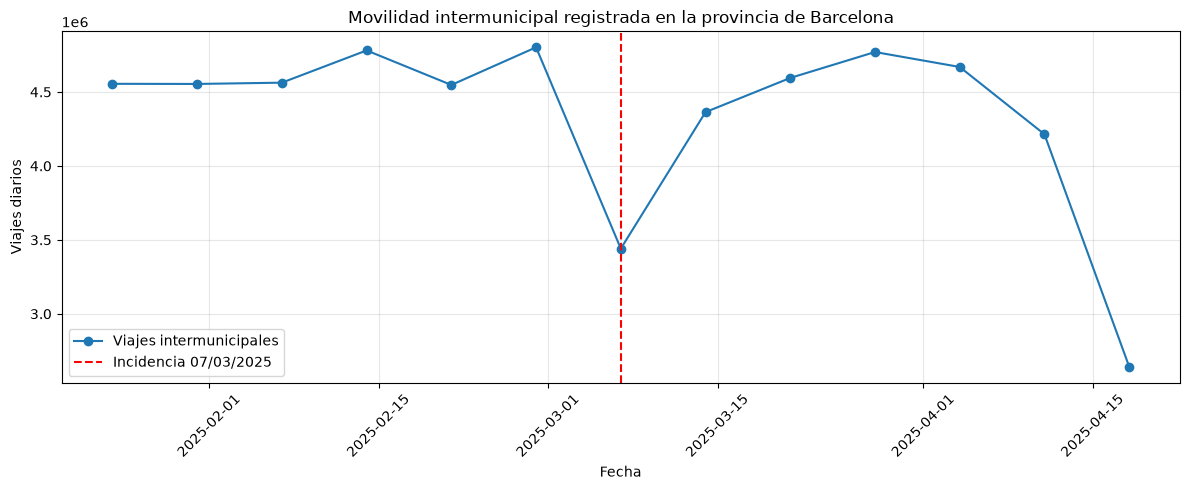

Viajes registrados el 07/03: 3,440,596
Mediana otros viernes: 4,555,222
Variación provincial: -24.47%
Viernes de control: 9


In [29]:

plt.figure(figsize=(12, 5))

plt.plot(
    viernes["day"],
    viernes["viajes_totales"],
    marker="o",
    label="Viajes intermunicipales"
)

plt.axvline(
    fecha_incidencia,
    color="red",
    linestyle="--",
    label="Incidencia 07/03/2025"
)

plt.title(
    "Movilidad intermunicipal registrada en la provincia de Barcelona"
)

plt.xlabel("Fecha")
plt.ylabel("Viajes diarios")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Comparación con viernes sin incidencias registradas
controles_provinciales = viernes[
    (~viernes["es_incidencia"])
    & (~viernes["es_festivo"])
    & (~viernes["incidencia_registrada"])
]

dia_incidencia = viernes[
    viernes["es_incidencia"]
]

if len(dia_incidencia) == 1 and not controles_provinciales.empty:

    viajes_incidencia = dia_incidencia[
        "viajes_totales"
    ].iloc[0]

    mediana_controles = controles_provinciales[
        "viajes_totales"
    ].median()

    variacion_provincial = (
        (viajes_incidencia - mediana_controles)
        / mediana_controles * 100
    )

    print(
        f"Viajes registrados el 07/03: "
        f"{viajes_incidencia:,.0f}"
    )
    print(
        f"Mediana otros viernes: "
        f"{mediana_controles:,.0f}"
    )
    print(
        f"Variación provincial: "
        f"{variacion_provincial:+.2f}%"
    )
    print(
        f"Viernes de control: "
        f"{len(controles_provinciales)}"
    )
else:
    print("No hay suficientes datos para la comparación.")



### 5.4. Comprobación de la consistencia de los datos

El 7 de marzo de 2025 presenta una reducción importante del volumen provincial de viajes y del número de registros disponibles.

Para investigar si esta reducción corresponde a una variación puntual o a un posible problema de cobertura, se examina la evolución diaria durante la semana de la incidencia.

Se comparan el total de viajes, el número de registros y la media de viajes por registro.

El objetivo es identificar cambios abruptos en las características del conjunto de datos antes de interpretar las desviaciones como efectos asociados a Rodalies.


C:\Users\marti\AppData\Local\Temp\ipykernel_137776\1510758280.py:26: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(diagnostico_datos.round(2))


,day,viajes_totales,registros,viajes_por_registro,dia_semana
0,2025-03-03,4340096.0,67382,64.41,Monday
1,2025-03-04,4792484.0,67588,70.91,Tuesday
2,2025-03-05,4839349.0,67668,71.52,Wednesday
3,2025-03-06,4682754.0,66772,70.13,Thursday
4,2025-03-07,3440596.0,60243,57.11,Friday
5,2025-03-08,3098981.0,60203,51.48,Saturday
6,2025-03-09,2430925.0,59821,40.64,Sunday
7,2025-03-10,4374142.0,65770,66.51,Monday
8,2025-03-11,4463869.0,65206,68.46,Tuesday


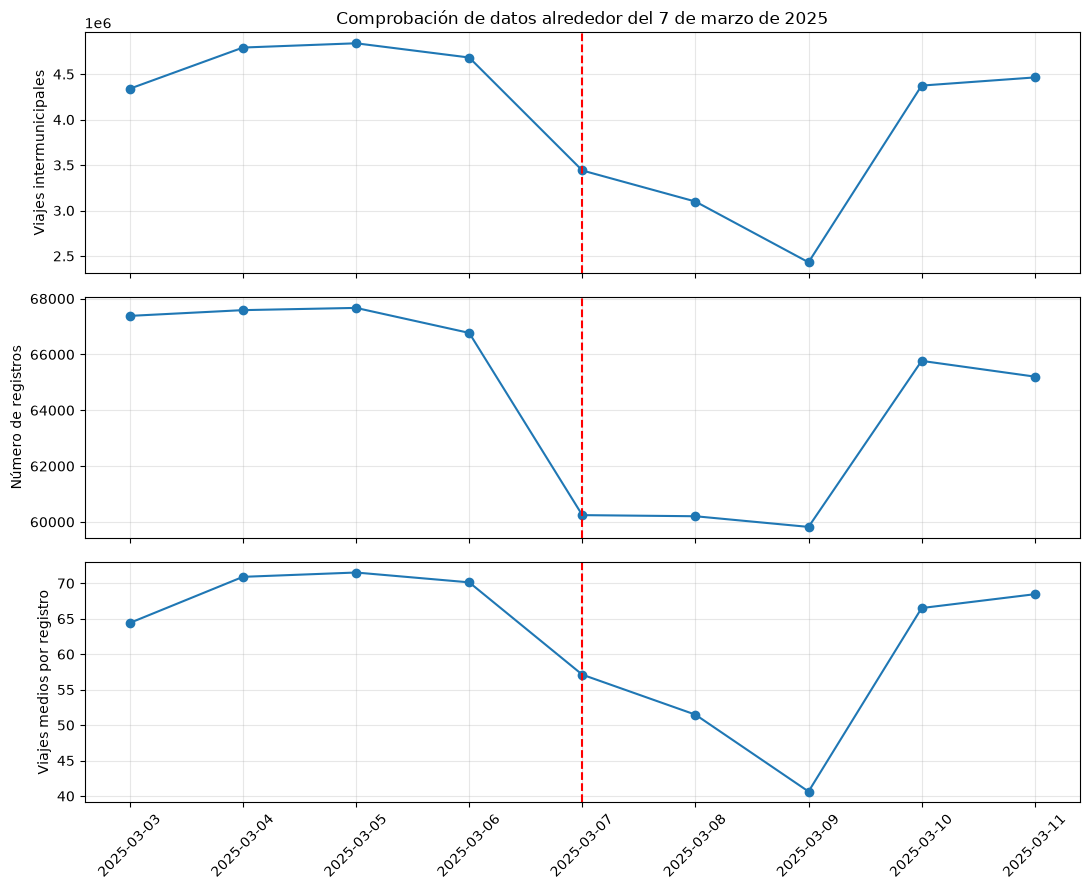

In [30]:

# Movilidad provincial alrededor de la incidencia
diagnostico_datos = con.execute(
    """
    SELECT
        day,
        SUM(viajes) AS viajes_totales,
        COUNT(*) AS registros,
        AVG(viajes) AS viajes_por_registro
    FROM read_parquet(?)
    WHERE day BETWEEN '2025-03-03' AND '2025-03-11'
      AND municipio_origen <> municipio_destino
    GROUP BY day
    ORDER BY day
    """,
    [str(M2_PATH)]
).df()

diagnostico_datos["day"] = pd.to_datetime(
    diagnostico_datos["day"]
)

diagnostico_datos["dia_semana"] = (
    diagnostico_datos["day"].dt.day_name()
)

display(diagnostico_datos.round(2))

# Visualizar los tres indicadores
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

indicadores = [
    ("viajes_totales", "Viajes intermunicipales"),
    ("registros", "Número de registros"),
    ("viajes_por_registro", "Viajes medios por registro")
]

for ax, (columna, titulo) in zip(axes, indicadores):

    ax.plot(
        diagnostico_datos["day"],
        diagnostico_datos[columna],
        marker="o"
    )

    ax.axvline(
        pd.Timestamp("2025-03-07"),
        color="red",
        linestyle="--"
    )

    ax.set_ylabel(titulo)
    ax.grid(alpha=0.3)

axes[0].set_title(
    "Comprobación de datos alrededor del 7 de marzo de 2025"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## 6. Segundo caso de estudio: 5 de junio de 2025

### 6.1. Comprobación inicial de la movilidad provincial

Se analiza la incidencia del 5 de junio de 2025, que afectó a varias líneas de Rodalies en Barcelona.

Antes de evaluar relaciones OD concretas, se comprueba el volumen general de movilidad intermunicipal registrado por Telefónica durante esa fecha.

Se compara el número de viajes y registros del día de incidencia con otros jueves próximos sin incidencias registradas ni festivos.

Esta comprobación busca identificar posibles anomalías generales de cobertura o movilidad que puedan dificultar la interpretación territorial de los resultados.


In [31]:

fecha_incidencia_junio = pd.Timestamp("2025-06-05")

inicio = fecha_incidencia_junio - pd.Timedelta(days=42)
fin = fecha_incidencia_junio + pd.Timedelta(days=42)

# Movilidad provincial en el período de referencia
movilidad_junio = con.execute(
    """
    SELECT
        day,
        SUM(viajes) AS viajes_totales,
        COUNT(*) AS registros,
        AVG(viajes) AS viajes_por_registro
    FROM read_parquet(?)
    WHERE day BETWEEN ? AND ?
      AND municipio_origen <> municipio_destino
    GROUP BY day
    ORDER BY day
    """,
    [str(M2_PATH), inicio.date(), fin.date()]
).df()

movilidad_junio["day"] = pd.to_datetime(
    movilidad_junio["day"]
)

# Comparar únicamente jueves
jueves = movilidad_junio[
    movilidad_junio["day"].dt.day_of_week == 3
].copy()

jueves["es_incidencia"] = (
    jueves["day"] == fecha_incidencia_junio
)

jueves["es_festivo"] = [
    fecha.date() in festivos_cat
    for fecha in jueves["day"]
]

jueves["incidencia_registrada"] = (
    jueves["day"].isin(fechas_con_incidencias)
)

display(jueves.round(2))

# Jueves de referencia
controles_junio = jueves[
    (~jueves["es_incidencia"])
    & (~jueves["es_festivo"])
    & (~jueves["incidencia_registrada"])
]

dia_junio = jueves[
    jueves["es_incidencia"]
]

if len(dia_junio) == 1 and not controles_junio.empty:

    for indicador in [
        "viajes_totales",
        "registros",
        "viajes_por_registro"
    ]:

        observado = dia_junio[indicador].iloc[0]
        referencia = controles_junio[indicador].median()

        diferencia = (
            (observado - referencia)
            / referencia * 100
        )

        print(
            f"{indicador}: "
            f"{observado:,.2f} | "
            f"Mediana controles: {referencia:,.2f} | "
            f"Variación: {diferencia:+.2f}%"
        )

    print("Jueves de control:", len(controles_junio))

else:
    print("No hay suficientes datos para comparar.")


C:\Users\marti\AppData\Local\Temp\ipykernel_137776\2908457099.py:45: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(jueves.round(2))


,day,viajes_totales,registros,viajes_por_registro,es_incidencia,es_festivo,incidencia_registrada
0,2025-04-24,4784828.0,69668,68.68,False,False,False
7,2025-05-01,2816391.0,67572,41.68,False,True,False
14,2025-05-08,4739883.0,68679,69.02,False,False,False
21,2025-05-15,4744166.0,68513,69.24,False,False,False
27,2025-05-22,4497714.0,68036,66.11,False,False,False
34,2025-05-29,4849314.0,70631,68.66,False,False,False
41,2025-06-05,4689530.0,68736,68.23,True,False,True
48,2025-06-12,4883696.0,69728,70.04,False,False,False
55,2025-06-19,4855249.0,70634,68.74,False,False,False
62,2025-06-26,4796227.0,70727,67.81,False,False,False


viajes_totales: 4,689,530.00 | Mediana controles: 4,744,166.00 | Variación: -1.15%
registros: 68,736.00 | Mediana controles: 70,631.00 | Variación: -2.68%
viajes_por_registro: 68.23 | Mediana controles: 68.66 | Variación: -0.63%
Jueves de control: 11



### 6.2. Análisis territorial de las relaciones OD

La comprobación provincial no muestra una anomalía general de volumen o cobertura comparable a la observada el 7 de marzo.

Se analizarán ahora relaciones OD vinculadas a los corredores ferroviarios afectados por la incidencia del 5 de junio de 2025.

Para cada relación se calcularán:

- Viajes observados y esperados.
- Desviación porcentual del día de incidencia.
- Mediana de las desviaciones de otros jueves próximos.
- Diferencia respecto a los días de referencia.

Se analizarán ambos sentidos de desplazamiento para identificar posibles diferencias territoriales.

Las desviaciones representan cambios respecto a la movilidad estimada y no permiten identificar directamente los usuarios afectados por Rodalies.


In [32]:

# Municipios candidatos de los corredores afectados
municipios_junio = {
    "08121": "Mataró",
    "08096": "Granollers",
    "08088": "La Garriga",
    "08187": "Sabadell",
    "08279": "Terrassa",
    "08056": "Castelldefels"
}

codigo_barcelona = "08019"

resultados_junio = []

for codigo, municipio in municipios_junio.items():

    # Analizar ambos sentidos
    sentidos = [
        (codigo, codigo_barcelona, f"{municipio} → Barcelona"),
        (codigo_barcelona, codigo, f"Barcelona → {municipio}")
    ]

    for origen, destino, nombre in sentidos:

        predicciones = estimar_movilidad(origen, destino)

        predicciones["Relacion"] = nombre
        predicciones["municipio_origen"] = origen
        predicciones["municipio_destino"] = destino

        resultados_junio.append(predicciones)

movilidad_junio_od = pd.concat(
    resultados_junio,
    ignore_index=True
)

print(
    "Relaciones analizadas:",
    movilidad_junio_od["Relacion"].nunique()
)

# Resultados del día de incidencia
resultados_incidencia_junio = movilidad_junio_od[
    movilidad_junio_od["day"] == fecha_incidencia_junio
].copy()

display(
    resultados_incidencia_junio[
        [
            "Relacion",
            "viajes_observados",
            "viajes_esperados",
            "desviacion_pct"
        ]
    ].sort_values("desviacion_pct").round(2)
)


Relaciones analizadas: 12


,Relacion,viajes_observados,viajes_esperados,desviacion_pct
2585,Castelldefels → Barcelona,14392.0,16368.11,-12.07
2828,Barcelona → Castelldefels,14755.0,16537.99,-10.78
641,Granollers → Barcelona,9118.0,9249.22,-1.42
155,Mataró → Barcelona,12275.0,12427.41,-1.23
884,Barcelona → Granollers,9136.0,9122.04,0.15
398,Barcelona → Mataró,13551.0,13428.55,0.91
2099,Terrassa → Barcelona,18669.0,18451.68,1.18
1856,Barcelona → Sabadell,22870.0,22181.29,3.10
1613,Sabadell → Barcelona,23951.0,23149.39,3.46
2342,Barcelona → Terrassa,18881.0,18080.73,4.43


In [33]:

resultados_controles_junio = []

for relacion, grupo in movilidad_junio_od.groupby("Relacion"):

    dia = grupo[
        grupo["day"] == fecha_incidencia_junio
    ]

    if dia.empty or pd.isna(dia["desviacion_pct"].iloc[0]):
        continue

    controles = grupo[
        (grupo["day"] >= fecha_incidencia_junio - pd.Timedelta(days=42))
        & (grupo["day"] <= fecha_incidencia_junio + pd.Timedelta(days=42))
        & (grupo["day"] != fecha_incidencia_junio)
        & (grupo["day"].dt.day_of_week == fecha_incidencia_junio.day_of_week)
        & (grupo["es_festivo"] == 0)
        & (~grupo["day"].isin(fechas_con_incidencias))
    ].dropna(subset=["desviacion_pct"])

    if controles.empty:
        continue

    desviacion = dia["desviacion_pct"].iloc[0]
    mediana = controles["desviacion_pct"].median()
    p25 = controles["desviacion_pct"].quantile(0.25)
    p75 = controles["desviacion_pct"].quantile(0.75)

    resultados_controles_junio.append({
        "Relacion": relacion,
        "Desviacion incidencia (%)": desviacion,
        "Mediana controles (%)": mediana,
        "Diferencia (pp)": desviacion - mediana,
        "P25 controles (%)": p25,
        "P75 controles (%)": p75,
        "N controles": len(controles),
        "Fuera de P25-P75": desviacion < p25 or desviacion > p75
    })

comparacion_junio = pd.DataFrame(
    resultados_controles_junio
).sort_values("Diferencia (pp)")

display(comparacion_junio.round(2))


,Relacion,Desviacion incidencia (%),Mediana controles (%),Diferencia (pp),P25 controles (%),P75 controles (%),N controles,Fuera de P25-P75
0,Barcelona → Castelldefels,-10.78,-1.27,-9.51,-3.90,4.39,11,True
6,Castelldefels → Barcelona,-12.07,-7.13,-4.94,-12.06,-5.02,11,True
9,Mataró → Barcelona,-1.23,-0.28,-0.95,-1.42,2.28,11,False
11,Terrassa → Barcelona,1.18,1.98,-0.80,-1.35,4.40,11,False
1,Barcelona → Granollers,0.15,0.52,-0.37,-2.22,2.69,11,False
7,Granollers → Barcelona,-1.42,-1.12,-0.30,-7.72,0.19,11,False
10,Sabadell → Barcelona,3.46,3.57,-0.11,1.31,4.38,11,False
3,Barcelona → Mataró,0.91,0.91,-0.00,-0.99,3.11,11,False
4,Barcelona → Sabadell,3.10,1.49,1.62,-0.19,3.28,11,False
8,La Garriga → Barcelona,9.84,7.95,1.89,-0.35,13.03,11,False



### 6.3. Visualización de las desviaciones territoriales

Se representan las diferencias entre las desviaciones del 5 de junio de 2025 y las medianas obtenidas en los jueves de referencia.

Los valores negativos indican una movilidad inferior a la desviación habitual estimada para esa relación OD. Los positivos indican una movilidad superior.

La visualización permite identificar relaciones con comportamientos diferenciados, pero no permite atribuir directamente estas variaciones a la incidencia ferroviaria.


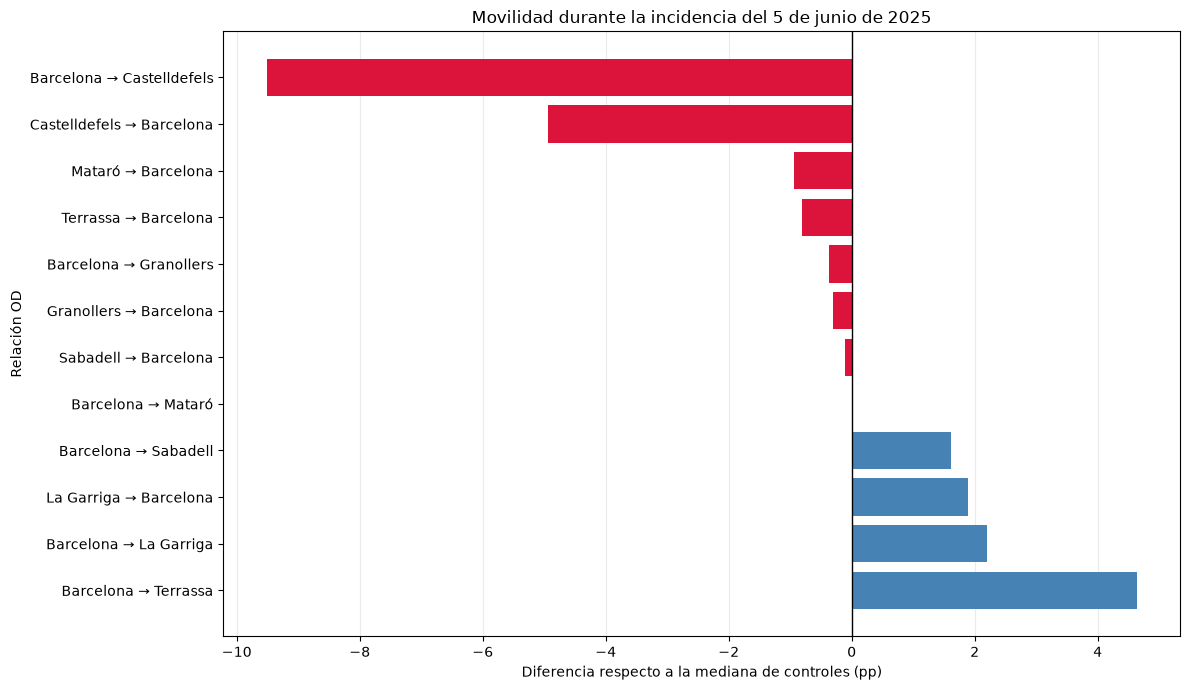

In [34]:

# Ordenar relaciones según su diferencia respecto a controles
grafico_junio = comparacion_junio.sort_values(
    "Diferencia (pp)"
).copy()

fig, ax = plt.subplots(figsize=(12, 7))

# Diferencias negativas y positivas
colores = [
    "crimson" if valor < 0 else "steelblue"
    for valor in grafico_junio["Diferencia (pp)"]
]

ax.barh(
    grafico_junio["Relacion"],
    grafico_junio["Diferencia (pp)"],
    color=colores
)

ax.axvline(0, color="black", linewidth=1)

ax.set_xlabel(
    "Diferencia respecto a la mediana de controles (pp)"
)
ax.set_ylabel("Relación OD")
ax.set_title(
    "Movilidad durante la incidencia del 5 de junio de 2025"
)

ax.invert_yaxis()
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



### 6.4. Ampliación del análisis al corredor sur

Las relaciones Barcelona–Castelldefels presentan las mayores desviaciones negativas respecto a los jueves comparables del 5 de junio de 2025.

Para comprobar si este comportamiento se extiende a otros municipios próximos, se amplía el análisis a las 20 relaciones OD seleccionadas previamente para el corredor sur.

Se aplica el mismo modelo de regresión y se compara cada desviación con la mediana de los jueves próximos sin incidencias registradas ni festivos.

El objetivo es identificar posibles patrones territoriales, evitando interpretar automáticamente las desviaciones como consecuencias de la incidencia ferroviaria.


In [35]:

resultados_sur_junio = []

for relacion, grupo in movilidad_esperada.groupby("Relacion"):

    dia = grupo[
        grupo["day"] == fecha_incidencia_junio
    ]

    if dia.empty or pd.isna(dia["desviacion_pct"].iloc[0]):
        continue

    controles = grupo[
        (grupo["day"] >= fecha_incidencia_junio - pd.Timedelta(days=42))
        & (grupo["day"] <= fecha_incidencia_junio + pd.Timedelta(days=42))
        & (grupo["day"] != fecha_incidencia_junio)
        & (grupo["day"].dt.day_of_week == fecha_incidencia_junio.day_of_week)
        & (grupo["es_festivo"] == 0)
        & (~grupo["day"].isin(fechas_con_incidencias))
    ].dropna(subset=["desviacion_pct"])

    if controles.empty:
        continue

    desviacion = dia["desviacion_pct"].iloc[0]
    mediana = controles["desviacion_pct"].median()
    p25 = controles["desviacion_pct"].quantile(0.25)
    p75 = controles["desviacion_pct"].quantile(0.75)

    resultados_sur_junio.append({
        "Relacion": relacion,
        "Desviacion incidencia (%)": desviacion,
        "Mediana controles (%)": mediana,
        "Diferencia (pp)": desviacion - mediana,
        "P25 controles (%)": p25,
        "P75 controles (%)": p75,
        "N controles": len(controles),
        "Fuera de P25-P75": desviacion < p25 or desviacion > p75
    })

comparacion_sur_junio = pd.DataFrame(
    resultados_sur_junio
).sort_values("Diferencia (pp)")

display(comparacion_sur_junio.round(2))


,Relacion,Desviacion incidencia (%),Mediana controles (%),Diferencia (pp),P25 controles (%),P75 controles (%),N controles,Fuera de P25-P75
15,Gavà → Viladecans,14.16,33.04,-18.88,21.26,36.60,11,True
0,Barcelona → Castelldefels,-10.78,-1.27,-9.51,-3.90,4.39,11,True
19,Viladecans → Gavà,13.04,19.91,-6.87,18.56,31.44,11,True
1,Barcelona → El Prat de Llobregat,-6.40,-1.18,-5.22,-6.23,1.48,11,True
11,El Prat de Llobregat → Viladecans,7.48,12.50,-5.01,4.66,19.47,11,False
4,Castelldefels → Barcelona,-12.07,-7.13,-4.94,-12.06,-5.02,11,True
17,Viladecans → Castelldefels,-5.86,-0.94,-4.91,-2.24,1.77,11,True
2,Barcelona → Gavà,0.06,4.36,-4.29,0.39,7.62,11,True
7,Castelldefels → Viladecans,3.62,7.67,-4.05,2.43,10.20,11,False
5,Castelldefels → El Prat de Llobregat,-2.76,0.15,-2.91,-3.06,3.54,11,False



### 6.5. Comprobación de los resultados con movilidad observada

Las diferencias respecto a las predicciones de la regresión muestran comportamientos distintos entre las relaciones OD del corredor sur.

Sin embargo, algunas relaciones presentan desviaciones sistemáticas importantes respecto al modelo.

Para comprobar la robustez de los resultados, se realizará una segunda comparación utilizando únicamente los viajes observados.

Para cada relación OD, se comparará el número de viajes registrado el 5 de junio con la mediana de los viajes observados durante los jueves próximos sin festivos ni incidencias registradas.

Esta comprobación permitirá identificar si los patrones encontrados también aparecen independientemente del modelo de regresión.


In [36]:

resultados_observados_junio = []

for relacion, grupo in movilidad_esperada.groupby("Relacion"):

    # Movilidad observada el 5 de junio
    dia = grupo[
        grupo["day"] == fecha_incidencia_junio
    ]

    if dia.empty:
        continue

    viajes_dia = dia["viajes_observados"].iloc[0]

    # Jueves comparables
    controles = grupo[
        (grupo["day"] >= fecha_incidencia_junio - pd.Timedelta(days=42))
        & (grupo["day"] <= fecha_incidencia_junio + pd.Timedelta(days=42))
        & (grupo["day"] != fecha_incidencia_junio)
        & (grupo["day"].dt.day_of_week == fecha_incidencia_junio.day_of_week)
        & (grupo["es_festivo"] == 0)
        & (~grupo["day"].isin(fechas_con_incidencias))
    ].dropna(subset=["viajes_observados"])

    if controles.empty or pd.isna(viajes_dia):
        continue

    mediana_viajes = controles["viajes_observados"].median()

    diferencia_pct = (
        100 * (viajes_dia - mediana_viajes) / mediana_viajes
        if mediana_viajes > 0 else np.nan
    )

    resultados_observados_junio.append({
        "Relacion": relacion,
        "Viajes 5 junio": viajes_dia,
        "Mediana jueves": mediana_viajes,
        "Diferencia observada (%)": diferencia_pct,
        "N controles": len(controles)
    })

comparacion_observada_junio = pd.DataFrame(
    resultados_observados_junio
)

# Añadir la diferencia calculada con la regresión
comparacion_robustez_junio = comparacion_observada_junio.merge(
    comparacion_sur_junio[
        ["Relacion", "Diferencia (pp)"]
    ],
    on="Relacion",
    how="left"
)

comparacion_robustez_junio = (
    comparacion_robustez_junio
    .sort_values("Diferencia observada (%)")
    .reset_index(drop=True)
)

display(comparacion_robustez_junio.round(2))


,Relacion,Viajes 5 junio,Mediana jueves,Diferencia observada (%),N controles,Diferencia (pp)
0,Barcelona → Castelldefels,14755.0,16698.0,-11.64,11,-9.51
1,Gavà → Viladecans,2834.0,3129.0,-9.43,11,-18.88
2,Viladecans → Castelldefels,6624.0,6959.0,-4.81,11,-4.91
3,Castelldefels → Barcelona,14392.0,15105.0,-4.72,11,-4.94
4,Barcelona → Gavà,10897.0,11430.0,-4.66,11,-4.29
5,El Prat de Llobregat → Castelldefels,6289.0,6582.0,-4.45,11,0.77
6,El Prat de Llobregat → Viladecans,5947.0,6216.0,-4.33,11,-5.01
7,Barcelona → Viladecans,16507.0,17216.0,-4.12,11,-2.36
8,Viladecans → Gavà,2789.0,2876.0,-3.03,11,-6.87
9,Castelldefels → Viladecans,7333.0,7512.0,-2.38,11,-4.05



### 6.6. Evolución temporal de las relaciones destacadas

Se analiza la evolución diaria de Barcelona → Castelldefels, una de las relaciones que presenta mayores diferencias negativas el 5 de junio de 2025.

Se representan los viajes observados y esperados durante las tres semanas anteriores y posteriores a la incidencia.

El objetivo es comprobar si la reducción se concentra en la fecha estudiada o forma parte de una evolución temporal más amplia.

También se incorpora una relación de referencia, Mataró → Barcelona, para contextualizar el comportamiento observado.


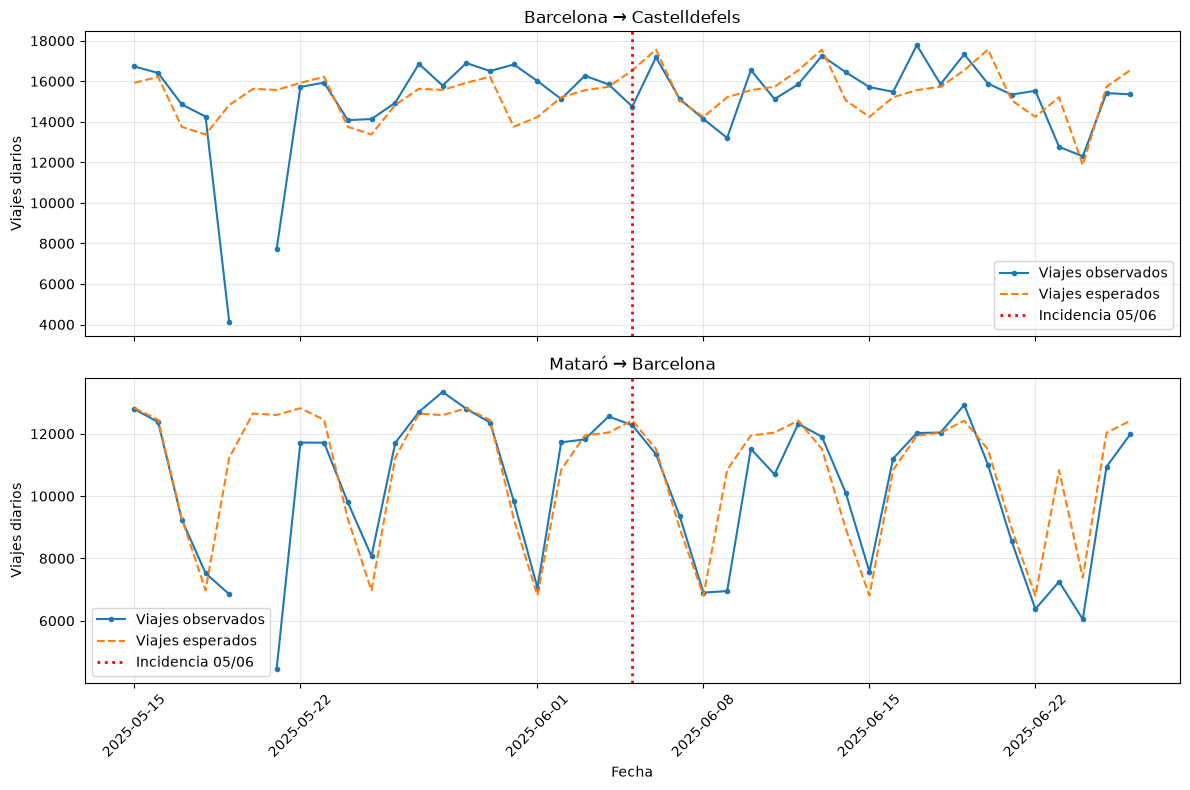

In [37]:

fecha = pd.Timestamp("2025-06-05")

relaciones_grafico = [
    "Barcelona → Castelldefels",
    "Mataró → Barcelona"
]

fig, axes = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True
)

for ax, relacion in zip(axes, relaciones_grafico):

    datos = movilidad_junio_od[
        (movilidad_junio_od["Relacion"] == relacion)
        & (
            movilidad_junio_od["day"].between(
                fecha - pd.Timedelta(days=21),
                fecha + pd.Timedelta(days=21)
            )
        )
    ].sort_values("day")

    ax.plot(
        datos["day"],
        datos["viajes_observados"],
        marker="o",
        markersize=3,
        label="Viajes observados"
    )

    ax.plot(
        datos["day"],
        datos["viajes_esperados"],
        linestyle="--",
        label="Viajes esperados"
    )

    ax.axvline(
        fecha,
        color="red",
        linestyle=":",
        linewidth=2,
        label="Incidencia 05/06"
    )

    ax.set_title(relacion)
    ax.set_ylabel("Viajes diarios")
    ax.legend()
    ax.grid(alpha=0.3)

plt.xlabel("Fecha")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## 7. Visualización de las alteraciones territoriales

### 7.1. Comparación de relaciones OD del corredor sur

Se representan las diferencias de movilidad de las 20 relaciones OD del corredor sur durante el 5 de junio de 2025.

Para cada relación se muestra la diferencia, en puntos porcentuales, entre la desviación calculada mediante la regresión y la mediana de los jueves comparables.

Esta visualización permite identificar qué relaciones presentan mayores alteraciones respecto a su comportamiento habitual.

Las diferencias observadas no pueden atribuirse directamente a la incidencia ferroviaria, ya que los datos no permiten identificar el modo de transporte utilizado.


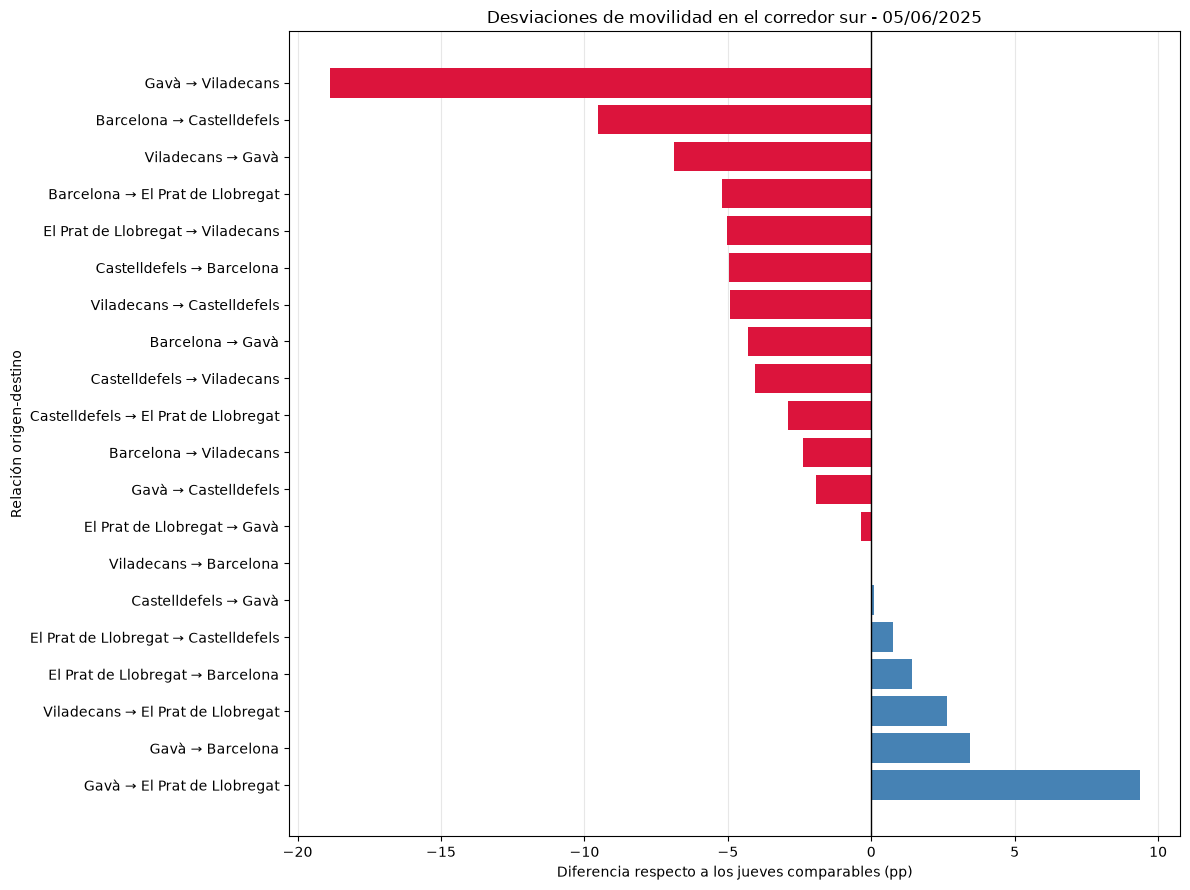

In [41]:

# Ordenar las 20 relaciones por diferencia respecto a controles
grafico_sur = comparacion_sur_junio.sort_values(
    "Diferencia (pp)"
).copy()

fig, ax = plt.subplots(figsize=(12, 9))

colores = [
    "crimson" if valor < 0 else "steelblue"
    for valor in grafico_sur["Diferencia (pp)"]
]

ax.barh(
    grafico_sur["Relacion"],
    grafico_sur["Diferencia (pp)"],
    color=colores
)

ax.axvline(0, color="black", linewidth=1)

ax.set_title(
    "Desviaciones de movilidad en el corredor sur - 05/06/2025"
)

ax.set_xlabel(
    "Diferencia respecto a los jueves comparables (pp)"
)

ax.set_ylabel("Relación origen-destino")

ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [42]:

import json

# Incorporar datos diarios a los resultados territoriales
datos_dashboard = comparacion_sur_junio.merge(
    movilidad_esperada[
        movilidad_esperada["day"] == fecha_incidencia_junio
    ][
        [
            "Relacion",
            "municipio_origen",
            "municipio_destino",
            "viajes_observados",
            "viajes_esperados"
        ]
    ],
    on="Relacion",
    how="inner",
    validate="one_to_one"
)

# Preparar nombres de columnas para JavaScript
datos_dashboard = datos_dashboard.rename(columns={
    "Relacion": "relacion",
    "Diferencia (pp)": "diferencia_pp",
    "Desviacion incidencia (%)": "desviacion_pct",
    "Mediana controles (%)": "mediana_controles_pct",
    "P25 controles (%)": "p25_controles_pct",
    "P75 controles (%)": "p75_controles_pct",
    "N controles": "n_controles",
    "Fuera de P25-P75": "fuera_rango_intercuartil"
})

# Convertir a JSON
registros_json = json.loads(
    datos_dashboard.to_json(
        orient="records",
        force_ascii=False
    )
)

salida = {
    "proyecto": "R-MOVE",
    "fecha_incidencia": "2025-06-05",
    "descripcion": "Incidencia ferroviaria en Barcelona",
    "relaciones": registros_json
}

# Carpeta de exportación
output_dir = PROJECT_ROOT / "data" / "processed" / "rmove"
output_dir.mkdir(parents=True, exist_ok=True)

ruta_json = output_dir / "incidencia_2025_06_05.json"

with open(ruta_json, "w", encoding="utf-8") as f:
    json.dump(salida, f, ensure_ascii=False, indent=2)

print("Archivo generado:", ruta_json)
print("Relaciones exportadas:", len(registros_json))


Archivo generado: C:\Users\marti\R-MOVE\data\processed\rmove\incidencia_2025_06_05.json
Relaciones exportadas: 20
